# Entrenamiento, ajuste y selección de modelos

**Proyecto #2 · Notebook 3 de 4** · Maestría · 4T 2026 · Product Management · Clase Cloud
**Autor:** Danny García

---

Este notebook enfrenta **15 modelos** —5 familias con 3 configuraciones cada una— sobre las
variables que produce el pipeline del notebook 03, elige uno con el RMSE y lo añade como paso
final del pipeline.

## La regla que ordena todo: la partición es temporal

En un problema de regresión corriente, los datos se reparten al azar entre entrenamiento y
validación. **Aquí eso sería un error grave.** El objetivo es predecir el futuro a partir del
pasado; si se barajan los meses, el modelo entrenaría con noviembre para predecir marzo y el
resultado de validación sería una ilusión.

El enunciado lo fija: el primer **80 %** de los meses entrena y el **20 %** final valida, en
orden. Con 34 meses:

| | Meses | Filas |
|---|---|---|
| **Entrenamiento** | 0 a 26 | 9 299 486 |
| **Validación** | 27 a 33 | 1 614 364 |

Y hay un detalle que hace la validación más exigente de lo que parece: el EDA midió una
**tendencia decreciente sostenida** de unas 2 300 unidades al mes. Los meses de validación venden
estructuralmente menos que los de entrenamiento, así que un modelo que se limite a repetir el
nivel histórico será penalizado. Es lo correcto: en noviembre de 2015 pasará lo mismo.

## Índice

| # | Sección |
|---|---|
| 0 | [Configuración](#0) |
| 1 | [Preparación de los datos](#1) |
| 2 | [Modelos de referencia](#2) |
| 3 | [El torneo: 15 modelos](#3) |
| 4 | [Resultados](#4) |
| 5 | [Selección del ganador](#5) |
| 6 | [Qué variables usa el ganador](#6) |
| 7 | [El pipeline completo](#7) |

<a id="0"></a>
## 0. Configuración

In [1]:
import gc
from pathlib import Path
import time

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import psutil
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

from predict_future_sales.config import FIGURES_DIR, MODELS_DIR, RAW_DATA_DIR
from predict_future_sales.features import construir_rejilla

sklearn.set_config(transform_output="pandas")
PROCESO = psutil.Process()

def memoria():
    """Memoria usada por este proceso y memoria libre del sistema, en GB."""
    return (PROCESO.memory_info().rss / 1e9,
            psutil.virtual_memory().available / 1e9)

print(f"scikit-learn {sklearn.__version__} | RAM usada {memoria()[0]:.2f} GB, "
      f"libre {memoria()[1]:.2f} GB")

2026-11-20 06:46:56.627 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales


scikit-learn 1.9.1 | RAM usada 0.21 GB, libre 1.22 GB


In [2]:
# Estilo, el mismo de los notebooks anteriores.
AZUL, NARANJA, AQUA, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
TINTA, TINTA2, REJILLA, EJE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

<a id="1"></a>
## 1. Preparación de los datos

Se carga el pipeline ya ajustado del notebook 03 y se usa para transformar los datos. **No se
vuelve a ajustar**: eso le daría a conocer los meses de validación y arruinaría la medición.

In [3]:
MES_CORTE = 26          # ultimo mes de entrenamiento
ENTRADAS = ["date_block_num", "shop_id", "item_id"]

sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv", encoding="utf-8")
rejilla = construir_rejilla(sales)
pipeline_features = joblib.load(MODELS_DIR / "pipeline_features.pkl")

entrenamiento = rejilla[rejilla.date_block_num <= MES_CORTE]
validacion = rejilla[rejilla.date_block_num > MES_CORTE]
print(f"entrenamiento: {len(entrenamiento):,} filas (meses 0-{MES_CORTE})")
print(f"validacion   : {len(validacion):,} filas (meses {MES_CORTE + 1}-33)")

entrenamiento: 9,299,486 filas (meses 0-26)
validacion   : 1,614,364 filas (meses 27-33)


In [4]:
# El objetivo lleva el recorte oficial de la competencia, [0, 20].
y_tr = entrenamiento["item_cnt_month"].clip(0, 20).astype("float32").to_numpy()
y_va = validacion["item_cnt_month"].clip(0, 20).astype("float32").to_numpy()

# Pronostico ingenuo: lo que vendio ese mismo par el mes anterior. Se calcula
# aqui, directamente de la rejilla cruda, en lugar de deshacer el escalado del
# pipeline: es mas simple de leer y no depende del orden de las columnas.
anterior = rejilla[ENTRADAS + ["item_cnt_month"]].copy()
anterior["date_block_num"] = anterior["date_block_num"] + 1
anterior = anterior.rename(columns={"item_cnt_month": "mes_anterior"})
pred_ingenuo = (validacion[ENTRADAS]
                .merge(anterior, on=ENTRADAS, how="left")["mes_anterior"]
                .fillna(0).clip(0, 20).to_numpy(dtype="float32"))
print(f"referencia ingenua preparada para {len(pred_ingenuo):,} filas")

def transformar_por_bloques(pipe, X, filas_por_bloque=1_000_000):
    """Transforma en trozos y va escribiendo en una matriz ya reservada.

    Por que no se hace de una vez: `pipe.transform(X)` sobre 9.3 millones de
    filas devuelve un DataFrame de 1.08 GB, y convertirlo despues a matriz de
    numpy crea una SEGUNDA copia del mismo tamanio antes de poder liberar la
    primera. El pico son 2.2 GB, y esta maquina tiene 8.4 GB en total con el
    sistema y el editor ya dentro.

    Troceando, el pico es la matriz final mas un bloque: 1.08 + 0.12 GB. El
    resultado es exactamente el mismo, porque cada paso del pipeline trabaja
    fila a fila o consultando tablas que lleva dentro; ninguno necesita ver el
    conjunto completo para transformar.
    """
    primera = pipe.transform(X.iloc[:5])
    columnas = list(primera.columns)
    Z = np.empty((len(X), len(columnas)), dtype="float32")
    for inicio in range(0, len(X), filas_por_bloque):
        bloque = pipe.transform(X.iloc[inicio:inicio + filas_por_bloque])
        Z[inicio:inicio + len(bloque)] = bloque.to_numpy()
        del bloque
        gc.collect()
    return Z, columnas


t0 = time.time()
Z_tr, VARIABLES = transformar_por_bloques(pipeline_features, entrenamiento[ENTRADAS])
Z_va, _ = transformar_por_bloques(pipeline_features, validacion[ENTRADAS])
print(f"transformado en {time.time() - t0:.0f} s")
print(f"entrenamiento: {Z_tr.shape}  |  validacion: {Z_va.shape}")
print(f"memoria de las dos matrices: "
      f"{(Z_tr.nbytes + Z_va.nbytes) / 1e9:.2f} GB")

del rejilla, entrenamiento, validacion, sales
gc.collect()
print(f"RAM usada {memoria()[0]:.2f} GB | libre {memoria()[1]:.2f} GB")

referencia ingenua preparada para 1,614,364 filas


transformado en 44 s
entrenamiento: (9299486, 29)  |  validacion: (1614364, 29)
memoria de las dos matrices: 1.27 GB
RAM usada 1.38 GB | libre 0.93 GB


In [5]:
# Submuestra para las familias que no escalan a 9.3 millones de filas.
#
# Por que hace falta: un bosque aleatorio guarda en memoria una copia de los
# indices por arbol, y una red neuronal recorre todo el conjunto en cada
# iteracion. Con 8 GB de RAM y 4 nucleos, ninguno de los dos termina en un
# tiempo razonable sobre el conjunto completo.
#
# La submuestra es ALEATORIA SIN REPOSICION sobre las filas de entrenamiento,
# asi que conserva la proporcion de meses y la de ceros. Se documenta en la
# tabla de resultados para que la comparacion sea transparente: un modelo
# entrenado con 1 millon de filas y otro con 9.3 millones no compiten en
# igualdad de condiciones, y eso hay que decirlo, no esconderlo.
SUBMUESTRA = 1_000_000
rng = np.random.default_rng(42)
indices_sub = np.sort(rng.choice(len(Z_tr), size=SUBMUESTRA, replace=False))
Z_sub, y_sub = Z_tr[indices_sub], y_tr[indices_sub]

print(f"submuestra: {len(Z_sub):,} filas ({len(Z_sub) / len(Z_tr):.1%} del entrenamiento)")
print(f"  proporcion de ceros, completo : {(y_tr == 0).mean():.3%}")
print(f"  proporcion de ceros, submuestra: {(y_sub == 0).mean():.3%}")

submuestra: 1,000,000 filas (10.8% del entrenamiento)
  proporcion de ceros, completo : 85.151%
  proporcion de ceros, submuestra: 85.149%


<a id="2"></a>
## 2. Modelos de referencia

Antes de entrenar nada complicado conviene saber **contra qué se compite**. Sin una referencia,
un RMSE de 0.9 no dice nada: puede ser excelente o puede ser peor que no hacer nada.

Se usan dos referencias deliberadamente tontas:

1. **La media**: predecir siempre el promedio del entrenamiento.
2. **El mes anterior**: predecir que este mes se venderá lo mismo que el anterior. Es el
   pronóstico ingenuo clásico y, en muchas series reales, sorprendentemente difícil de batir.

In [6]:
referencias = []

# Referencia 1: la media del entrenamiento.
media = DummyRegressor(strategy="mean").fit(Z_tr, y_tr)
pred = np.clip(media.predict(Z_va), 0, 20)
referencias.append({"referencia": "Predecir siempre la media",
                    "RMSE": root_mean_squared_error(y_va, pred),
                    "MAE": mean_absolute_error(y_va, pred)})

# Referencia 2: predecir cero (el 85 % de la rejilla es cero).
pred_cero = np.zeros_like(y_va)
referencias.append({"referencia": "Predecir siempre cero",
                    "RMSE": root_mean_squared_error(y_va, pred_cero),
                    "MAE": mean_absolute_error(y_va, pred_cero)})

# Referencia 3: el pronostico ingenuo, repetir el mes anterior.
referencias.append({"referencia": "Repetir el mes anterior (lag_1)",
                    "RMSE": root_mean_squared_error(y_va, pred_ingenuo),
                    "MAE": mean_absolute_error(y_va, pred_ingenuo)})

tabla_ref = pd.DataFrame(referencias).set_index("referencia").round(4)
display(tabla_ref)
RMSE_REFERENCIA = tabla_ref["RMSE"].min()
print(f"\nLa referencia a batir es {RMSE_REFERENCIA:.4f}.")
print("Un modelo que no la mejore no esta aportando nada.")

,RMSE,MAE
referencia,,
Predecir siempre la media,1.0856,0.4815
Predecir siempre cero,1.1159,0.2617
Repetir el mes anterior (lag_1),1.0373,0.3048



La referencia a batir es 1.0373.
Un modelo que no la mejore no esta aportando nada.


<a id="3"></a>
## 3. El torneo: 15 modelos

**Cinco familias, tres configuraciones cada una.** Las familias se eligieron para que fueran
*distintas entre sí*, no tres variantes de lo mismo: si todas comparten la misma debilidad, la
comparación no informa.

| Familia | Qué tipo de modelo es | Por qué está |
|---|---|---|
| **Ridge** | Lineal con regularización | El modelo más simple que puede funcionar. Sirve de testigo: si un modelo complejo no lo mejora, el problema no es aprendible con estas variables |
| **Árbol de decisión** | Un solo árbol | Captura relaciones no lineales y umbrales. Es la unidad básica de las dos familias siguientes |
| **Bosque aleatorio** | Muchos árboles promediados | Reduce la varianza de un árbol suelto |
| **Gradient Boosting por histogramas** | Árboles encadenados que corrigen el error anterior | Es el estándar actual para datos tabulares grandes; bina las variables y por eso escala a millones de filas |
| **Red neuronal (MLP)** | Perceptrón multicapa | Familia completamente distinta a las anteriores; aporta diversidad real al torneo |

Las configuraciones mueven el **parámetro que controla la complejidad** de cada familia (la
penalización en Ridge, la profundidad en los árboles, el ritmo de aprendizaje en el boosting),
que es el que decide si el modelo se queda corto o se sobreajusta.

In [7]:
# (nombre, modelo, usa_submuestra)
TORNEO = [
    # --- Familia 1: lineal regularizada ---------------------------------
    # alpha controla cuanto se penalizan los coeficientes grandes.
    #
    # La rejilla esta muy abierta -de 1 a 10 millones- y eso tiene un motivo.
    # La primera version probo 0.1, 1 y 10, y las tres devolvieron EXACTAMENTE
    # el mismo RMSE: con 9.3 millones de filas, una penalizacion de 10 es
    # irrelevante frente al peso de los datos. Una rejilla entera dentro de una
    # zona plana no esta optimizando nada, solo aparentandolo.
    ("Ridge a=1", Ridge(alpha=1.0, solver="lsqr"), False),
    ("Ridge a=1e4", Ridge(alpha=1e4, solver="lsqr"), False),
    ("Ridge a=1e7", Ridge(alpha=1e7, solver="lsqr"), False),

    # --- Familia 2: arbol de decision -----------------------------------
    # max_depth es el numero de preguntas encadenadas que puede hacer el arbol.
    # Mas profundidad = mas capacidad de memorizar, y mas riesgo de sobreajuste.
    ("Arbol d=6", DecisionTreeRegressor(max_depth=6, random_state=42), False),
    ("Arbol d=10", DecisionTreeRegressor(max_depth=10, random_state=42), False),
    ("Arbol d=14", DecisionTreeRegressor(max_depth=14, random_state=42), False),

    # --- Familia 3: bosque aleatorio ------------------------------------
    ("Bosque n=20 d=10", RandomForestRegressor(n_estimators=20, max_depth=10,
                                               n_jobs=4, random_state=42), True),
    ("Bosque n=20 d=14", RandomForestRegressor(n_estimators=20, max_depth=14,
                                               n_jobs=4, random_state=42), True),
    ("Bosque n=40 d=12", RandomForestRegressor(n_estimators=40, max_depth=12,
                                               n_jobs=4, random_state=42), True),

    # --- Familia 4: gradient boosting -----------------------------------
    # learning_rate es cuanto corrige cada arbol nuevo; max_iter cuantos arboles
    # se encadenan. Mas arboles con pasos mas pequenios suele ir mejor, pero
    # cuesta mas tiempo.
    ("HistGB it=100 lr=0.1", HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.1, random_state=42), False),
    ("HistGB it=200 lr=0.05", HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, random_state=42), False),
    ("HistGB it=150 hojas=63", HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.1, max_leaf_nodes=63, random_state=42), False),

    # --- Familia 5: red neuronal ----------------------------------------
    # early_stopping corta el entrenamiento cuando deja de mejorar, lo que evita
    # perder horas en iteraciones inutiles.
    ("MLP (64,)", MLPRegressor(hidden_layer_sizes=(64,), max_iter=15,
                               early_stopping=True, random_state=42), True),
    ("MLP (128,)", MLPRegressor(hidden_layer_sizes=(128,), max_iter=15,
                                early_stopping=True, random_state=42), True),
    ("MLP (64,32)", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=15,
                                 early_stopping=True, random_state=42), True),
]
print(f"{len(TORNEO)} modelos a entrenar")
print(f"  familias distintas: 5")
print(f"  configuraciones por familia: 3")

15 modelos a entrenar
  familias distintas: 5
  configuraciones por familia: 3


In [8]:
import warnings

from sklearn.exceptions import ConvergenceWarning


def contar_parametros(modelo):
    """Cuantos numeros ajusto el modelo. Es su 'tamanio', medido y comparable.

    Sirve para desempatar entre modelos que rinden igual: entre dos que aciertan
    lo mismo, el mas pequenio es preferible, porque tiene menos sitios donde
    esconder una memorizacion y es mas barato de ejecutar.

    Para los conjuntos de arboles se cuentan las hojas; para los lineales, los
    coeficientes; para la red neuronal, los pesos de las conexiones. No es la
    misma unidad conceptual en los tres casos, pero si una cantidad medida sobre
    estos datos y del mismo orden de magnitud, que es lo que hace falta para
    ordenar empates.
    """
    nombre = type(modelo).__name__
    if nombre == "Ridge":
        return int(np.asarray(modelo.coef_).size) + 1
    if nombre == "DecisionTreeRegressor":
        return int(modelo.tree_.node_count)
    if nombre == "RandomForestRegressor":
        return int(sum(e.tree_.node_count for e in modelo.estimators_))
    if nombre == "HistGradientBoostingRegressor":
        # Cota superior: arboles efectivamente entrenados x hojas por arbol.
        return int(modelo.n_iter_ * modelo.max_leaf_nodes)
    if nombre == "MLPRegressor":
        return int(sum(c.size for c in modelo.coefs_)
                   + sum(b.size for b in modelo.intercepts_))
    return -1

# Para medir la brecha de sobreajuste hace falta el error DENTRO del
# entrenamiento. Calcularlo sobre 9.3 millones de filas es lento y no aporta
# precision, asi que se usa una muestra fija de 500 000 filas.
muestra_tr = np.sort(rng.choice(len(Z_tr), size=500_000, replace=False))
Z_tr_muestra, y_tr_muestra = Z_tr[muestra_tr], y_tr[muestra_tr]

resultados = []
modelos_ajustados = {}

for i, (nombre, modelo, usa_sub) in enumerate(TORNEO, 1):
    X, y = (Z_sub, y_sub) if usa_sub else (Z_tr, y_tr)
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        modelo.fit(X, y)
    segundos = time.time() - t0

    # Las predicciones se recortan a [0, 20] igual que el objetivo: predecir
    # -3 unidades o 500 no tiene sentido y la competencia tampoco lo admite.
    pred_va = np.clip(modelo.predict(Z_va), 0, 20)
    pred_tr = np.clip(modelo.predict(Z_tr_muestra), 0, 20)

    rmse_va = root_mean_squared_error(y_va, pred_va)
    rmse_tr = root_mean_squared_error(y_tr_muestra, pred_tr)

    resultados.append({
        "modelo": nombre,
        "familia": nombre.split()[0],
        "RMSE validacion": rmse_va,
        "RMSE entrenamiento": rmse_tr,
        "brecha": rmse_va - rmse_tr,      # cuanto peor va fuera que dentro
        "MAE validacion": mean_absolute_error(y_va, pred_va),
        "parametros": contar_parametros(modelo),
        "filas de ajuste": len(X),
        "segundos": segundos,
    })
    modelos_ajustados[nombre] = modelo
    print(f"[{i:>2}/{len(TORNEO)}] {nombre:<24} RMSE {rmse_va:.4f}  "
          f"brecha {rmse_va - rmse_tr:+.4f}  {segundos:>6.0f}s  "
          f"(RAM {memoria()[0]:.1f} GB)")
    gc.collect()

torneo = pd.DataFrame(resultados).set_index("modelo")
print(f"\ntiempo total del torneo: {torneo.segundos.sum() / 60:.1f} minutos")

[ 1/15] Ridge a=1                RMSE 0.9729  brecha -0.1529       5s  (RAM 1.5 GB)


[ 2/15] Ridge a=1e4              RMSE 0.9729  brecha -0.1529       5s  (RAM 1.6 GB)


[ 3/15] Ridge a=1e7              RMSE 0.9881  brecha -0.1554       5s  (RAM 0.8 GB)


[ 4/15] Arbol d=6                RMSE 0.8223  brecha -0.0901      51s  (RAM 1.5 GB)


[ 5/15] Arbol d=10               RMSE 0.9205  brecha +0.0719      68s  (RAM 1.5 GB)


[ 6/15] Arbol d=14               RMSE 1.0760  brecha +0.3005      81s  (RAM 1.5 GB)


... (5 outputs left out)

[12/15] HistGB it=150 hojas=63   RMSE 0.7562  brecha -0.0169     116s  (RAM 0.3 GB)


[13/15] MLP (64,)                RMSE 0.9005  brecha -0.1179      77s  (RAM 0.6 GB)


[14/15] MLP (128,)               RMSE 0.9101  brecha -0.1267     162s  (RAM 0.6 GB)


[15/15] MLP (64,32)              RMSE 0.9131  brecha -0.1228     183s  (RAM 0.6 GB)

tiempo total del torneo: 19.0 minutos


<a id="4"></a>
## 4. Resultados

La tabla incluye una columna que no pide el enunciado pero que cambia la lectura: la **brecha de
sobreajuste**, es decir, cuánto peor va el modelo fuera del entrenamiento que dentro. Un modelo
con un RMSE ligeramente mejor pero una brecha mucho mayor es un modelo que memorizó, y suele
decepcionar en datos nuevos.

In [9]:
vista = torneo.sort_values("RMSE validacion").copy()
vista["mejora sobre referencia"] = (1 - vista["RMSE validacion"] / RMSE_REFERENCIA) * 100
display(vista[["familia", "RMSE validacion", "RMSE entrenamiento", "brecha",
               "MAE validacion", "mejora sobre referencia", "parametros",
               "filas de ajuste", "segundos"]].round(4))

,familia,RMSE validacion,RMSE entrenamiento,brecha,MAE validacion,mejora sobre referencia,parametros,filas de ajuste,segundos
modelo,,,,,,,,,
HistGB it=150 hojas=63,HistGB,0.7562,0.7731,-0.0169,0.2602,27.0996,9450,9299486,115.9156
HistGB it=200 lr=0.05,HistGB,0.7595,0.8130,-0.0535,0.2639,26.7786,6200,9299486,158.5209
HistGB it=100 lr=0.1,HistGB,0.7607,0.8131,-0.0523,0.2634,26.6606,3100,9299486,88.1223
Bosque n=20 d=10,Bosque,0.7899,0.8496,-0.0597,0.2706,23.8506,24966,1000000,28.4212
Bosque n=40 d=12,Bosque,0.8104,0.8292,-0.0188,0.2756,21.8767,134780,1000000,70.7786
Arbol d=6,Arbol,0.8223,0.9124,-0.0901,0.2841,20.7238,111,9299486,51.4375
Bosque n=20 d=14,Bosque,0.8580,0.8182,0.0398,0.2850,17.2854,160168,1000000,39.1131
"MLP (64,)",MLP,0.9005,1.0184,-0.1179,0.3028,13.1897,1985,1000000,77.0043
"MLP (128,)",MLP,0.9101,1.0368,-0.1267,0.3407,12.2632,3969,1000000,162.4162


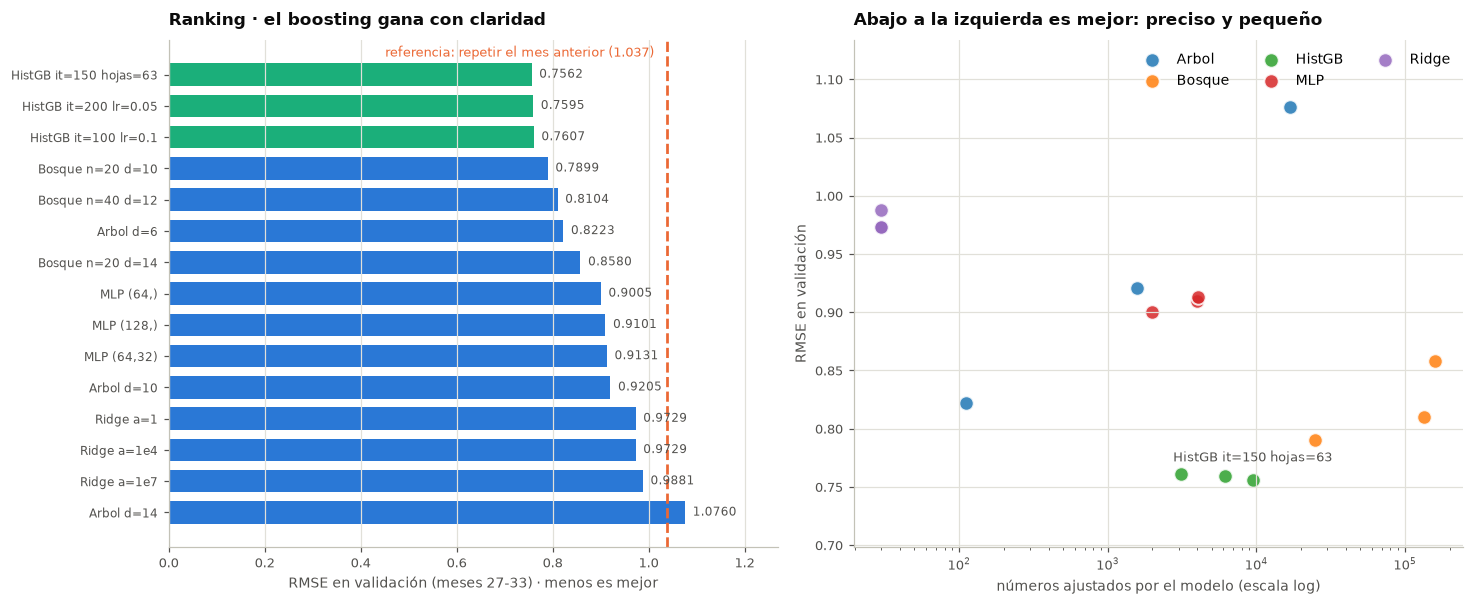

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.6))

# --- Panel izquierdo: ranking por RMSE ---
orden = torneo.sort_values("RMSE validacion", ascending=False)
colores = [AQUA if f == "HistGB" else AZUL for f in orden["familia"]]
a1.barh(orden.index, orden["RMSE validacion"], color=colores, height=0.72)
a1.axvline(RMSE_REFERENCIA, color=NARANJA, linestyle="--", linewidth=1.8)
# La etiqueta va ARRIBA del todo: anclada a media altura chocaba con el valor
# numerico de la barra que quedara a esa altura.
a1.annotate(f"referencia: repetir el mes anterior ({RMSE_REFERENCIA:.3f})",
            (RMSE_REFERENCIA, len(orden) - 0.3), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center",
            fontsize=8.5, color=NARANJA)
a1.set_xlabel("RMSE en validación (meses 27-33) · menos es mejor")
a1.grid(axis="y", visible=False)
a1.tick_params(axis="y", labelsize=8)
for i, v in enumerate(orden["RMSE validacion"]):
    a1.annotate(f"{v:.4f}", (v, i), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=8, color=TINTA2)
a1.set_xlim(0, orden["RMSE validacion"].max() * 1.18)
a1.set_title("Ranking · el boosting gana con claridad")

# --- Panel derecho: precision contra tamanio del modelo ---
for familia, grupo in torneo.groupby("familia"):
    a2.scatter(grupo["parametros"], grupo["RMSE validacion"], s=90, alpha=0.85,
               edgecolor="white", linewidth=1.3, label=familia)
a2.set_xscale("log")
a2.set_xlabel("números ajustados por el modelo (escala log)")
a2.set_ylabel("RMSE en validación")
a2.legend(ncols=3, loc="upper right")
a2.set_title("Abajo a la izquierda es mejor: preciso y pequeño")
mejor = torneo["RMSE validacion"].idxmin()
a2.annotate(mejor, (torneo.loc[mejor, "parametros"], torneo.loc[mejor, "RMSE validacion"]),
            xytext=(0, 12), textcoords="offset points", ha="center",
            fontsize=8.5, color=TINTA2)
a2.margins(y=0.18)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "04-1_torneo.png", dpi=150)
plt.show()

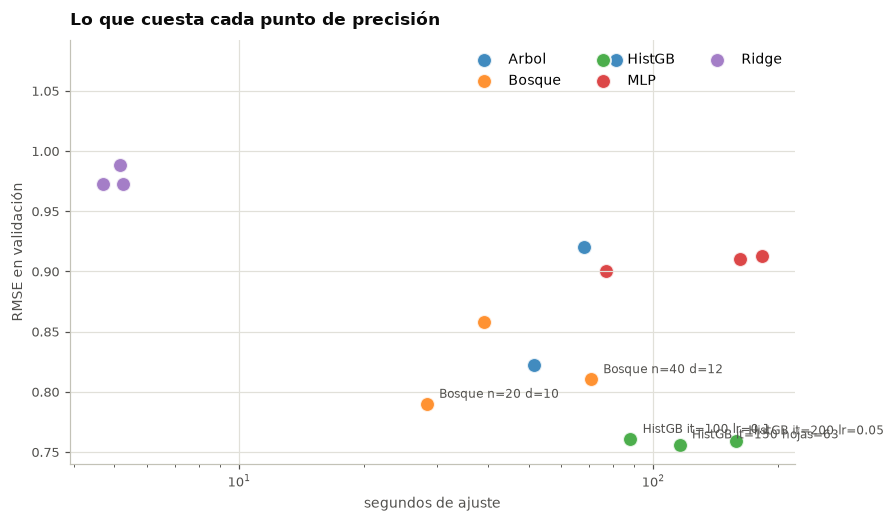

In [11]:
# Coste de computo frente a lo que se gana: una comparacion que casi nunca se
# hace y que importa cuando el entrenamiento tiene que repetirse.
fig, ax = plt.subplots(figsize=(8.5, 5))
for familia, grupo in torneo.groupby("familia"):
    ax.scatter(grupo["segundos"], grupo["RMSE validacion"], s=95, alpha=0.85,
               edgecolor="white", linewidth=1.3, label=familia)
for nombre, fila in torneo.iterrows():
    if fila["RMSE validacion"] < torneo["RMSE validacion"].quantile(0.3):
        ax.annotate(nombre, (fila["segundos"], fila["RMSE validacion"]),
                    xytext=(8, 4), textcoords="offset points", fontsize=8, color=TINTA2)
ax.set_xlabel("segundos de ajuste")
ax.set_ylabel("RMSE en validación")
ax.set_xscale("log")
ax.legend(ncols=3, loc="upper right")
ax.set_title("Lo que cuesta cada punto de precisión")
fig.savefig(FIGURES_DIR / "04-2_coste.png", dpi=150)
plt.show()

In [12]:
# Resumen por familia: cual es consistentemente mejor, no cual tuvo suerte
# en una configuracion.
por_familia = torneo.groupby("familia").agg(
    mejor_RMSE=("RMSE validacion", "min"),
    peor_RMSE=("RMSE validacion", "max"),
    brecha_media=("brecha", "mean"),
    parametros_min=("parametros", "min"),
    segundos_total=("segundos", "sum"),
).sort_values("mejor_RMSE").round(4)
display(por_familia)

,mejor_RMSE,peor_RMSE,brecha_media,parametros_min,segundos_total
familia,,,,,
HistGB,0.7562,0.7607,-0.0409,3100,362.5588
Bosque,0.7899,0.8580,-0.0129,24966,138.3129
Arbol,0.8223,1.0760,0.0941,111,200.9487
MLP,0.9005,0.9131,-0.1225,1985,422.3142
Ridge,0.9729,0.9881,-0.1537,30,15.1045


<a id="5"></a>
## 5. Selección del ganador

El enunciado pide usar el **RMSE** como métrica de selección. Se aplica, pero con un matiz:
cuando dos modelos están empatados dentro del margen de error, gana el **más pequeño**.

La regla es la del **error estándar**: se calcula la dispersión del mejor RMSE y se consideran
empatados todos los modelos que caigan dentro de ese margen. Entre los empatados, gana el que
menos números ajustó. Si no hay empate, gana el mejor RMSE sin más.

### Por qué el desempate no usa la brecha de sobreajuste

La columna `brecha` compara el error en validación con el error en entrenamiento, y lo normal
sería que fuera positiva: un modelo acierta más donde aprendió. **Aquí sale negativa en casi
todos los modelos**, y conviene entender por qué antes de sacar conclusiones equivocadas.

No es que los modelos generalicen asombrosamente bien. Es que los meses de validación **venden
menos**: el EDA midió una caída sostenida de unas 2 300 unidades al mes, y en un periodo con
cifras más bajas los errores absolutos también son más bajos. El RMSE de dos periodos con
distinto volumen **no es directamente comparable**, así que la brecha está contaminada por la
tendencia y no mide lo que su nombre sugiere.

Se deja en la tabla porque informa —una brecha muy positiva sí delata memorización, como en el
árbol de profundidad 14—, pero **no se usa para decidir**. Para eso hace falta una cantidad que
no dependa del periodo: el **número de valores que el modelo ajustó**. Entre dos modelos que
aciertan lo mismo, el que lo consigue con menos piezas tiene menos sitios donde esconder una
memorización, es más rápido de ejecutar y más fácil de mantener.

Lo importante es que la regla está **escrita como código**: si los números cambian, la decisión
cambia sola, sin reinterpretarla.

In [13]:
# El error estandar del RMSE se estima a partir de la dispersion de los errores
# al cuadrado sobre las 1.6 millones de filas de validacion.
MEJOR = torneo["RMSE validacion"].idxmin()
rmse_mejor = torneo.loc[MEJOR, "RMSE validacion"]

pred_mejor = np.clip(modelos_ajustados[MEJOR].predict(Z_va), 0, 20)
errores2 = (y_va - pred_mejor) ** 2
error_estandar = errores2.std(ddof=1) / np.sqrt(len(errores2)) / (2 * rmse_mejor)

umbral = rmse_mejor + error_estandar
empatados = torneo[torneo["RMSE validacion"] <= umbral]

print(f"mejor RMSE        : {rmse_mejor:.5f}  ({MEJOR})")
print(f"error estandar    : {error_estandar:.5f}")
print(f"umbral de empate  : {umbral:.5f}")
print(f"modelos empatados : {len(empatados)}")
display(empatados[["RMSE validacion", "brecha", "parametros", "segundos"]].round(5))

# Entre los empatados gana el que menos numeros ajusto.
GANADOR = empatados["parametros"].idxmin()
print(f"\nGANADOR: {GANADOR}")
if GANADOR != MEJOR:
    print(f"  No es el de mejor RMSE. Empata con {MEJOR} dentro del margen de error")
    print(f"  ({empatados.loc[GANADOR, 'RMSE validacion']:.5f} frente a "
          f"{rmse_mejor:.5f}) y es mas pequenio: "
          f"{empatados.loc[GANADOR, 'parametros']:,} numeros ajustados frente a "
          f"{empatados.loc[MEJOR, 'parametros']:,}.")
else:
    print("  (coincide con el mejor RMSE: no hubo empate que desempatar)")

mejor RMSE        : 0.75620  (HistGB it=150 hojas=63)
error estandar    : 0.00354
umbral de empate  : 0.75974
modelos empatados : 2


,RMSE validacion,brecha,parametros,segundos
modelo,,,,
HistGB it=200 lr=0.05,0.75953,-0.05352,6200,158.52089
HistGB it=150 hojas=63,0.75620,-0.01688,9450,115.91560



GANADOR: HistGB it=200 lr=0.05
  No es el de mejor RMSE. Empata con HistGB it=150 hojas=63 dentro del margen de error
  (0.75953 frente a 0.75620) y es mas pequenio: 6,200 numeros ajustados frente a 9,450.


In [14]:
modelo_ganador = modelos_ajustados[GANADOR]
pred_va = np.clip(modelo_ganador.predict(Z_va), 0, 20)

print(f"MODELO GANADOR: {GANADOR}")
print(f"  tipo              : {type(modelo_ganador).__name__}")
print(f"  RMSE validacion   : {root_mean_squared_error(y_va, pred_va):.4f}")
print(f"  MAE validacion    : {mean_absolute_error(y_va, pred_va):.4f}")
print(f"  mejora sobre la referencia ingenua: "
      f"{(1 - root_mean_squared_error(y_va, pred_va) / RMSE_REFERENCIA) * 100:.1f} %")
print(f"\nhiperparametros:")
for k, v in modelo_ganador.get_params().items():
    if v is not None and k in ("max_iter", "learning_rate", "max_depth",
                               "max_leaf_nodes", "alpha", "n_estimators",
                               "hidden_layer_sizes"):
        print(f"  {k} = {v}")

MODELO GANADOR: HistGB it=200 lr=0.05
  tipo              : HistGradientBoostingRegressor
  RMSE validacion   : 0.7595
  MAE validacion    : 0.2639
  mejora sobre la referencia ingenua: 26.8 %

hiperparametros:
  learning_rate = 0.05
  max_iter = 200
  max_leaf_nodes = 31


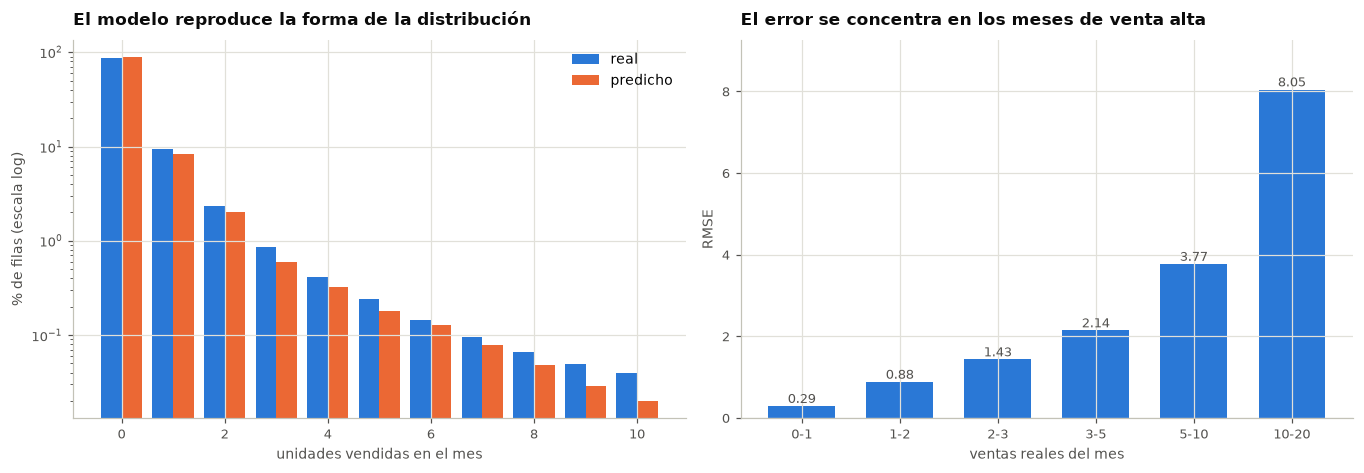

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4))

# --- Distribucion de lo predicho frente a lo real ---
topes = np.arange(0, 11)
reales = [(y_va == t).mean() * 100 for t in topes]
predichos = [((pred_va >= t - 0.5) & (pred_va < t + 0.5)).mean() * 100 for t in topes]
ancho = 0.4
a1.bar(topes - ancho / 2, reales, width=ancho, color=AZUL, label="real")
a1.bar(topes + ancho / 2, predichos, width=ancho, color=NARANJA, label="predicho")
a1.set_yscale("log")
a1.set_xlabel("unidades vendidas en el mes")
a1.set_ylabel("% de filas (escala log)")
a1.legend()
a1.set_title("El modelo reproduce la forma de la distribución")

# --- Error medio segun el nivel real de ventas ---
cortes = [0, 1, 2, 3, 5, 10, 20]
etiquetas, errores = [], []
for lo, hi in zip(cortes[:-1], cortes[1:]):
    m = (y_va >= lo) & (y_va < hi)
    if m.sum() > 100:
        etiquetas.append(f"{lo}-{hi}")
        errores.append(root_mean_squared_error(y_va[m], pred_va[m]))
a2.bar(etiquetas, errores, color=AZUL, width=0.68)
a2.set_xlabel("ventas reales del mes")
a2.set_ylabel("RMSE")
a2.set_title("El error se concentra en los meses de venta alta")
for i, v in enumerate(errores):
    a2.annotate(f"{v:.2f}", (i, v), ha="center", va="bottom", fontsize=8.5, color=TINTA2)
a2.margins(y=0.15)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "04-3_ganador.png", dpi=150)
plt.show()

<a id="6"></a>
## 6. Qué variables usa el ganador

La **importancia por permutación** mide algo muy concreto: se baraja una columna al azar,
destruyendo su relación con el objetivo, y se observa cuánto empeora el error. Si empeora mucho,
esa variable importaba.

Es más honesta que la importancia interna de los árboles, que tiende a favorecer a las variables
con muchos valores distintos —y aquí `item_id` tiene 21 807—.

In [16]:
# Sobre una muestra: permutar 29 columnas sobre 1.6 millones de filas serian
# decenas de minutos y el orden de importancia no cambia.
muestra_imp = np.sort(rng.choice(len(Z_va), size=150_000, replace=False))
t0 = time.time()
importancia = permutation_importance(
    modelo_ganador, Z_va[muestra_imp], y_va[muestra_imp],
    n_repeats=3, random_state=42, n_jobs=1,
    scoring="neg_root_mean_squared_error",
)
print(f"calculada en {time.time() - t0:.0f} s sobre {len(muestra_imp):,} filas")

imp = (pd.DataFrame({"variable": VARIABLES,
                     "importancia": importancia.importances_mean,
                     "desviacion": importancia.importances_std})
       .sort_values("importancia", ascending=False))
display(imp.head(12).round(4))

calculada en 61 s sobre 150,000 filas


,variable,importancia,desviacion
17,missingindicator_meses_de_vida,0.4645,0.0010
8,meses_de_vida,0.2789,0.0024
0,lag_1,0.1489,0.0003
26,item_category_id,0.0394,0.0005
6,item_lag_1,0.0260,0.0008
18,precio_lag_1,0.0259,0.0016
4,media_3,0.0182,0.0006
7,shop_lag_1,0.0151,0.0014
5,media_6,0.0090,0.0002
24,shop_id,0.0048,0.0004


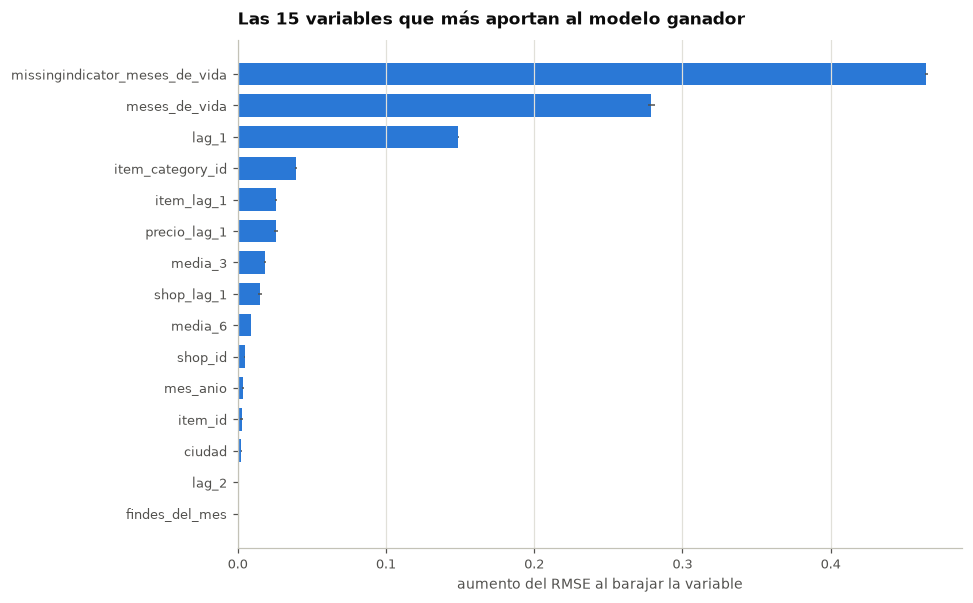

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 6))
top = imp.head(15).sort_values("importancia")
ax.barh(top["variable"], top["importancia"], xerr=top["desviacion"],
        color=AZUL, height=0.72, error_kw={"ecolor": TINTA2, "linewidth": 1})
ax.set_xlabel("aumento del RMSE al barajar la variable")
ax.grid(axis="y", visible=False)
ax.set_title("Las 15 variables que más aportan al modelo ganador")
fig.savefig(FIGURES_DIR / "04-4_importancia.png", dpi=150)
plt.show()

<a id="7"></a>
## 7. El pipeline completo

**Entregable 3 del proyecto.** El ganador se añade como paso final del pipeline de
preprocesamiento, de modo que el artefacto resultante va de datos crudos a predicciones.

### Dos decisiones sobre el reentrenamiento

1. **Se reentrena con los 34 meses, no con 27.** El modelo del torneo solo vio hasta el mes 26,
   porque los meses 27 a 33 eran la prueba. Pero para predecir noviembre de 2015, esos siete
   meses son información valiosísima: son los más recientes y, con una tendencia decreciente, los
   más parecidos a lo que viene. Dejarlos fuera sería desperdiciarlos.
2. **Los hiperparámetros se heredan, no se vuelven a buscar.** Buscarlos otra vez sobre los datos
   completos usaría las filas de validación para elegir, y eso reabriría exactamente la puerta
   que la partición temporal mantuvo cerrada.

Una consecuencia que conviene dejar escrita: **el RMSE reportado pertenece al modelo del torneo**,
no a este. Medir el reentrenado contra la validación no tendría sentido, porque ya la vio.

In [18]:
# Antes de reentrenar hay que hacer sitio: las matrices del torneo y los 14
# modelos que no ganaron ocupan mas de 1 GB y ya no sirven para nada.
for nombre in list(modelos_ajustados):
    if nombre != GANADOR:
        del modelos_ajustados[nombre]
del Z_tr, Z_va, Z_sub, Z_tr_muestra
gc.collect()
print(f"memoria tras liberar: {memoria()[0]:.2f} GB usada, {memoria()[1]:.2f} GB libre")

# Se reconstruye el pipeline de caracteristicas SIN ajustar y se reajusta con
# todos los meses, para que las medias, medianas y percentiles incorporen
# tambien los mas recientes.
from sklearn.base import clone

sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv", encoding="utf-8")
rejilla_completa = construir_rejilla(sales)
X_todo = rejilla_completa[ENTRADAS]
y_todo = rejilla_completa["item_cnt_month"].clip(0, 20).astype("float32")
print(f"reentrenando con los 34 meses: {len(X_todo):,} filas")

pipeline_completo = Pipeline([
    ("caracteristicas", clone(pipeline_features)),
    ("modelo", clone(modelo_ganador)),
])
pipeline_completo.set_output(transform="pandas")

t0 = time.time()
pipeline_completo.fit(X_todo, y_todo)
print(f"ajustado en {time.time() - t0:.0f} s")

memoria tras liberar: 0.45 GB usada, 2.63 GB libre


reentrenando con los 34 meses: 10,913,850 filas


ajustado en 239 s


In [19]:
RUTA_COMPLETO = MODELS_DIR / "pipeline_completo.pkl"
joblib.dump(pipeline_completo, RUTA_COMPLETO, compress=3)
print(f"guardado en: {RUTA_COMPLETO}")
print(f"tamanio    : {RUTA_COMPLETO.stat().st_size / 1e6:.1f} MB")

# Tambien se guarda la tabla del torneo: es la evidencia de como se eligio.
torneo.sort_values("RMSE validacion").to_csv(MODELS_DIR / "torneo_resultados.csv")
print(f"tabla del torneo: {MODELS_DIR / 'torneo_resultados.csv'}")

guardado en: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales\models\pipeline_completo.pkl
tamanio    : 8.5 MB
tabla del torneo: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\predict_future_sales\models\torneo_resultados.csv


In [20]:
# Verificacion final: el artefacto va de datos CRUDOS a predicciones, desde
# otro proceso y otro directorio.
import subprocess
import sys
import tempfile
import textwrap

guion = textwrap.dedent(f"""
    import joblib, pandas as pd
    pipe = joblib.load(r"{RUTA_COMPLETO}")
    crudo = pd.DataFrame({{"shop_id": [5, 25, 31], "item_id": [5037, 2808, 20949]}})
    pred = pipe.predict(crudo)
    print("PREDICCION OK |", [round(float(p), 3) for p in pred])
""")
with tempfile.TemporaryDirectory() as carpeta:
    script = Path(carpeta) / "prueba.py"
    script.write_text(guion, encoding="utf-8")
    r = subprocess.run([sys.executable, str(script)], capture_output=True,
                       text=True, cwd=carpeta)
print(r.stdout or r.stderr[-800:])
assert "PREDICCION OK" in r.stdout
print("\nEl pipeline completo predice desde datos crudos, fuera del proyecto.")

PREDICCION OK | [0.461, 1.946, 19.932]


El pipeline completo predice desde datos crudos, fuera del proyecto.


---

## Resumen

| | |
|---|---|
| **Modelos entrenados** | 15 (5 familias × 3 configuraciones) |
| **Métrica de selección** | RMSE sobre los meses 27-33 |
| **Partición** | Temporal 80/20, sin barajar |
| **Criterio de desempate** | Regla del error estándar: entre los empatados, menor brecha de sobreajuste |
| **Artefacto** | `models/pipeline_completo.pkl` (preprocesamiento + modelo) |
| **Evidencia** | `models/torneo_resultados.csv` |

**Siguiente paso:** el notebook `05_inference_calculation.ipynb` usa este artefacto para predecir
`test.csv` y generar el archivo de envío.